# 03 · Validación integrada: tracking + equipos + roles sobre coordenadas de campo

**Objetivo:** validar el pipeline completo sobre un vídeo independiente, resolviendo además el rol de cada identidad (jugador, portero, árbitro, fuera de campo) mediante coordenadas de campo obtenidas por homografía.

**Diseño:** la clasificación de equipos es un problema de color (modelo equipación-césped). El rol es un problema de semántica espacial, irresoluble en píxeles (portero y juez de línea son indistinguibles en imagen) y trivial en metros: quien se proyecta fuera del rectángulo del campo es asistente/staff; el outlier de color anclado junto a una portería es el portero (equipo por voto de proximidad); el outlier móvil dentro del campo es el árbitro.

**Salidas:** vídeo anotado con equipos y roles, precisión de clasificación sobre m uestra manual, y JSON con posiciones de campo (interfaz de la fase 5).

**Importante:** reiniciar el kernel antes de ejecutar (estado del tracker).vale con esto que has hecho te cargas al arbtro de campo(lo asigna como jugador del equpo de blanco y negro) pero si que pone bien al portero del lado izquierod pero no el del derecho. Creo que todos estos problemas se solucionarian si se creara otro dataset mucho mas amplio autoetiquetado con el existente para crear un modelo de deteccion de jugadores mas preciso

In [1]:
import json
import cv2
import numpy as np
from pathlib import Path
from collections import defaultdict, deque
from ultralytics import YOLO

REPO_ROOT = Path("../..").resolve()

# ===== PARÁMETRO =====
VIDEO_IN = REPO_ROOT / "data" / "raw" / "test (27).mp4"
# =====================

NOMBRE = VIDEO_IN.stem.replace(" ", "_").replace("(", "").replace(")", "")
detector = YOLO(str(REPO_ROOT / "models" / "best_v4.pt"))
kp_model = YOLO(str(REPO_ROOT / "models" / "keypoints_base.pt"))

tracker_cfg = REPO_ROOT / "configs" / "botsort_custom.yaml"
tracker_cfg.parent.mkdir(parents=True, exist_ok=True)
if not tracker_cfg.exists():
    tracker_cfg.write_text("""tracker_type: botsort
track_high_thresh: 0.25
track_low_thresh: 0.1
new_track_thresh: 0.6
track_buffer: 120
match_thresh: 0.8
fuse_score: true
gmc_method: sparseOptFlow
proximity_thresh: 0.5
appearance_thresh: 0.25
with_reid: true
model: auto
""", encoding="utf-8")

KP_REALES = np.array([
    (0,0),(0,68),(105,0),(105,68),(16.5,13.84),(16.5,54.16),(88.5,13.84),(88.5,54.16),
    (5.5,24.84),(5.5,43.16),(99.5,24.84),(99.5,43.16),(11,34),(94,34),(52.5,34),
    (52.5,0),(52.5,68),(0,13.84),(0,54.16),(105,13.84),
    (0,30.34),(0,37.66),(105,30.34),(105,37.66)], dtype=np.float32)
EXCLUIR_KP = {14, 15, 16}
PORTERIAS = np.array([[0.0, 34.0], [105.0, 34.0]])

print(f"Vídeo existe: {VIDEO_IN.exists()} | Nombre: {NOMBRE}")

Vídeo existe: True | Nombre: test_27


In [2]:
# ---- 1. Tracking + división por clase + cosido + filtro de espurios (pipeline de fase 4) ----
frames_dets = []
results = detector.track(source=str(VIDEO_IN), stream=True, persist=True,
                         tracker=str(tracker_cfg), conf=0.25, imgsz=1280, verbose=False)
for n, rd in enumerate(results):
    dets = []
    if rd.boxes is not None and rd.boxes.id is not None:
        for (x1, y1, x2, y2), tid, c in zip(rd.boxes.xyxy.cpu().numpy(),
                                            rd.boxes.id.cpu().numpy().astype(int),
                                            rd.boxes.cls.cpu().numpy().astype(int)):
            dets.append((int(tid), float(x1), float(y1), float(x2), float(y2), int(c)))
    frames_dets.append(dets)
    if (n + 1) % 100 == 0:
        print(f"Tracking: {n + 1} frames...")
N_FRAMES = len(frames_dets)

tracks_full = defaultdict(list)
for f_idx, dets in enumerate(frames_dets):
    for (tid, x1, y1, x2, y2, c) in dets:
        tracks_full[tid].append((f_idx, (x1 + x2) / 2, y2, int(c)))

MIN_SEG = 15
tracks2, clase2, mapa_det = {}, {}, {}
next_id = 1
for tid, pts in tracks_full.items():
    segs, actual, pendiente, c_actual = [], [], [], None
    for p in pts:
        c = p[3]
        if c_actual is None:
            c_actual = c
        if c == c_actual:
            if pendiente:
                actual.extend([(f, x, y, c_actual) for (f, x, y, _) in pendiente]); pendiente = []
            actual.append(p)
        else:
            pendiente.append(p)
            if len(pendiente) >= MIN_SEG:
                if actual:
                    segs.append((c_actual, actual))
                c_actual, actual, pendiente = c, [(f, x, y, c) for (f, x, y, _) in pendiente], []
    if pendiente:
        actual.extend([(f, x, y, c_actual) for (f, x, y, _) in pendiente])
    if actual:
        segs.append((c_actual, actual))
    for c_seg, seg in segs:
        nid = next_id; next_id += 1
        tracks2[nid] = [(f, x, y) for (f, x, y, c) in seg]
        clase2[nid] = c_seg
        for (f, x, y, c) in seg:
            mapa_det[(f, tid)] = nid

MAX_GAP, MAX_SOLAPE, RADIO_BASE, RADIO_POR_FRAME, RADIO_SOLAPE = 75, 12, 50, 5, 35
resumen, pos_pf = {}, {}
for nid, pts in tracks2.items():
    if clase2[nid] not in (1, 2) or len(pts) < 3:
        continue
    arr = np.array(pts); ult = arr[-5:]
    dt = ult[-1, 0] - ult[0, 0]
    vel = (ult[-1, 1:] - ult[0, 1:]) / dt if dt > 0 else np.zeros(2)
    resumen[nid] = {"ini": int(arr[0, 0]), "fin": int(arr[-1, 0]),
                    "pos_ini": arr[0, 1:], "pos_fin": arr[-1, 1:], "vel": vel}
    pos_pf[nid] = {int(f): np.array([x, y]) for f, x, y in pts}

cands = []
for ta, ra in resumen.items():
    for tb, rb in resumen.items():
        if ta == tb or clase2[ta] != clase2[tb]:
            continue
        gap = rb["ini"] - ra["fin"]
        if gap > MAX_GAP or gap < -MAX_SOLAPE:
            continue
        if gap > 0:
            d = np.linalg.norm(rb["pos_ini"] - (ra["pos_fin"] + ra["vel"] * gap))
            r = RADIO_BASE + RADIO_POR_FRAME * gap
        else:
            pa = pos_pf[ta].get(rb["ini"])
            if pa is None:
                continue
            d, r = np.linalg.norm(rb["pos_ini"] - pa), RADIO_SOLAPE
        if d <= r:
            cands.append((d, ta, tb))
cands.sort()
uf, ui, fusion = set(), set(), {}
for d, ta, tb in cands:
    if ta in uf or tb in ui:
        continue
    fusion[tb] = ta; uf.add(ta); ui.add(tb)
def raiz(t):
    while t in fusion:
        t = fusion[t]
    return t
mapa_final = {nid: raiz(nid) for nid in resumen}

# ---- Filtro de segmentos espurios -------------------------------------------
# Un segmento es ESPURIO si dura muy pocos frames Y solapa temporalmente con otro
# segmento de su MISMA clase (tras el cosido): es una doble caja del detector, no
# una identidad. No se filtra por duración a secas (un segmento corto pero solo
# puede ser una entrada/salida real de cuadro). Diagnóstico en test (27): los
# segmentos 31/37/88/89/90 (1-2 det) solapaban con el árbitro 15 -> cajas fantasma.
MIN_DET_SEG = 5     # menos detecciones que esto = candidato a espurio

# Rango temporal e id raíz (clase) de cada segmento consolidado
rango_seg = {nid: (int(arr[0, 0]), int(arr[-1, 0]))
             for nid, pts in tracks2.items() if len(pts) > 0
             for arr in [np.array(pts)]}
raiz_de = {nid: int(mapa_final.get(nid, nid)) for nid in tracks2}

espurios = set()
for nid, pts in tracks2.items():
    if len(pts) >= MIN_DET_SEG:
        continue
    if nid not in rango_seg:
        continue
    a0, a1 = rango_seg[nid]
    cls_a = clase2[nid]
    # ¿solapa con OTRO segmento de la misma clase (raíz distinta) y más largo?
    for otro, pts2 in tracks2.items():
        if otro == nid or clase2[otro] != cls_a or len(pts2) < MIN_DET_SEG:
            continue
        if raiz_de[otro] == raiz_de[nid]:
            continue   # mismo objeto cosido: no es competencia, es continuidad
        b0, b1 = rango_seg[otro]
        if not (a1 < b0 or a0 > b1):   # hay solapamiento temporal
            espurios.add(nid)
            break

print(f"Segmentos espurios filtrados (< {MIN_DET_SEG} det y solapan con misma clase): "
      f"{len(espurios)} -> {sorted(espurios)}")

frames_track = []
for f_idx, dets in enumerate(frames_dets):
    fr = []
    for (tid, x1, y1, x2, y2, c) in dets:
        if c in (1, 2):
            nid = mapa_det.get((f_idx, tid), tid)
            if nid in espurios:           # detección de un segmento espurio: se descarta
                continue
            idf = int(mapa_final.get(nid, nid))
        else:
            idf = int(tid)
        fr.append({"id": idf, "bbox": [x1, y1, x2, y2], "cls": c})
    frames_track.append(fr)
print(f"IDs de persona tras post-procesado: "
      f"{len({d['id'] for fr in frames_track for d in fr if d['cls'] in (1, 2)})}")

Tracking: 100 frames...
Tracking: 200 frames...
Tracking: 300 frames...
Tracking: 400 frames...
Tracking: 500 frames...
Tracking: 600 frames...
Tracking: 700 frames...
Segmentos espurios filtrados (< 5 det y solapan con misma clase): 14 -> [25, 31, 37, 54, 66, 68, 69, 70, 71, 81, 88, 89, 90, 95]
IDs de persona tras post-procesado: 49


In [3]:
# ---- 2. Pasada única de vídeo: homografía VALIDADA + PROPAGADA + colores + proyección ----
# Cambios clave frente a la versión anterior:
#   - Cada homografía se VALIDA geométricamente antes de usarse (rechaza las degeneradas que
#     proyectan jugadores a miles de metros o colapsan el campo a una línea).
#   - Solo las homografías válidas entran al historial (antes se promediaban buenas con malas,
#     contaminando la media). En frames sin homografía válida propia, se PROPAGA la última
#     buena estimando el movimiento de cámara por flujo óptico (paneo suave).

def homografia_valida(H, w_img, h_img):
    """Válida si proyecta el rectángulo del campo de vuelta a la imagen como un cuadrilátero
    convexo, de área razonable y sin mandar puntos al infinito."""
    if H is None:
        return False
    try:
        Hinv = np.linalg.inv(H)
    except np.linalg.LinAlgError:
        return False
    esq_campo = np.array([[[0,0]],[[105,0]],[[105,68]],[[0,68]]], dtype=np.float32)
    esq_img = cv2.perspectiveTransform(esq_campo, Hinv).reshape(-1,2)
    if not np.all(np.isfinite(esq_img)):
        return False
    margen = 3.0
    if (esq_img[:,0].min() < -margen*w_img or esq_img[:,0].max() > (1+margen)*w_img or
        esq_img[:,1].min() < -margen*h_img or esq_img[:,1].max() > (1+margen)*h_img):
        return False
    area = cv2.contourArea(esq_img.astype(np.float32))
    if area < 0.01 * w_img * h_img:
        return False
    if not cv2.isContourConvex(esq_img.astype(np.float32)):
        return False
    return True

def kp_dispersos(pts_img, w_img, h_img, min_frac=0.15):
    """True si los keypoints abarcan al menos min_frac del ancho Y del alto de la imagen."""
    if len(pts_img) < 4:
        return False
    ancho = pts_img[:,0].max() - pts_img[:,0].min()
    alto  = pts_img[:,1].max() - pts_img[:,1].min()
    return ancho >= min_frac * w_img and alto >= min_frac * h_img

def calcular_H(frame):
    """H solo si hay >=4 keypoints REPARTIDOS y la homografía resultante es válida."""
    h_img, w_img = frame.shape[:2]
    r = kp_model(frame, verbose=False, conf=0.25)[0]
    if r.keypoints is None:
        return None
    xy = r.keypoints.xy[0].cpu().numpy()
    cf = r.keypoints.conf[0].cpu().numpy()
    idx = [i for i in range(24) if cf[i] > 0.5 and i not in EXCLUIR_KP]
    if len(idx) < 4:
        return None
    src = xy[idx]
    if not kp_dispersos(src, w_img, h_img):
        return None
    H, _ = cv2.findHomography(src, KP_REALES[idx], cv2.RANSAC, 3.0)
    if not homografia_valida(H, w_img, h_img):
        return None
    return H

def color_camiseta(frame, bbox):
    x1, y1, x2, y2 = [int(v) for v in bbox]
    hb, wb = y2 - y1, x2 - x1
    if hb < 10 or wb < 4:
        return None
    crop = frame[max(y1 + int(0.22 * hb), 0):y1 + int(0.50 * hb),
                 max(x1 + int(0.25 * wb), 0):x2 - int(0.25 * wb)]
    if crop.size == 0:
        return None
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    pix = crop[cv2.inRange(hsv, (35, 40, 40), (85, 255, 255)) == 0].astype(np.float32)
    if len(pix) < 30:
        return None
    if len(pix) > 300:
        pix = pix[np.random.default_rng(0).choice(len(pix), 300, replace=False)]
    if len(pix) < 60:
        return pix.mean(axis=0)
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
    _, lb, ct = cv2.kmeans(pix, 3, None, crit, 3, cv2.KMEANS_PP_CENTERS)
    return ct[np.bincount(lb.ravel()).argmax()]

# Parámetros de propagación por flujo óptico (paneo suave)
FEAT_PARAMS = dict(maxCorners=400, qualityLevel=0.01, minDistance=7, blockSize=7)
LK_PARAMS = dict(winSize=(21, 21), maxLevel=3,
                 criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
MIN_PTS_FLUJO = 12
MAX_DESPL_MEDIO = 80.0

colores_det = {}    # (f, id) -> (BGR, peso)   solo cls 1
campo_det = {}      # (f, id) -> (X, Y) metros  cls 1 y 2
historial_H = deque(maxlen=5)   # SOLO homografías válidas (anclas)

H_vigente = None    # homografía en uso: media de anclas (reanclaje) o propagada
gris_prev = None
n_real = n_propag = n_guarda = n_sin = 0

cap = cv2.VideoCapture(str(VIDEO_IN))
for f_idx, dets in enumerate(frames_track):
    ret, frame = cap.read()
    if not ret:
        break
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    H_real = calcular_H(frame)

    if H_real is not None:
        # Ancla válida: reancla la homografía vigente a la media de anclas recientes (anti-temblor)
        historial_H.append(H_real)
        H_vigente = np.mean(np.array(historial_H), axis=0)
        n_real += 1
    else:
        # Sin homografía válida: propagar la vigente con el movimiento de cámara
        ok = False
        if H_vigente is not None and gris_prev is not None:
            p0 = cv2.goodFeaturesToTrack(gris_prev, mask=None, **FEAT_PARAMS)
            if p0 is not None and len(p0) >= MIN_PTS_FLUJO:
                p1, st, _ = cv2.calcOpticalFlowPyrLK(gris_prev, gris, p0, None, **LK_PARAMS)
                if p1 is not None:
                    good = st.ravel() == 1
                    a, b = p0[good].reshape(-1,2), p1[good].reshape(-1,2)
                    if len(a) >= MIN_PTS_FLUJO and np.linalg.norm(b-a, axis=1).mean() <= MAX_DESPL_MEDIO:
                        H_mov, inl = cv2.findHomography(a, b, cv2.RANSAC, 3.0)
                        if H_mov is not None and inl is not None and inl.sum() >= MIN_PTS_FLUJO:
                            H_vigente = H_vigente @ np.linalg.inv(H_mov)
                            ok = True
        if ok:
            n_propag += 1
        elif H_vigente is not None:
            n_guarda += 1     # se mantiene la vigente sin propagar
        else:
            n_sin += 1

    # Proyectar con la homografía vigente (reanclada o propagada)
    for d in dets:
        if d["cls"] not in (1, 2):
            continue
        x1, y1, x2, y2 = d["bbox"]
        if H_vigente is not None:
            pie = np.array([[[(x1 + x2) / 2, y2]]], dtype=np.float32)
            X, Y = cv2.perspectiveTransform(pie, H_vigente)[0][0]
            campo_det[(f_idx, d["id"])] = (float(X), float(Y))
        if d["cls"] == 1:
            c = color_camiseta(frame, d["bbox"])
            if c is not None:
                colores_det[(f_idx, d["id"])] = (c, y2 - y1)

    gris_prev = gris
    if (f_idx + 1) % 100 == 0:
        print(f"Análisis: {f_idx + 1}/{N_FRAMES} frames...")
cap.release()

print(f"\nHomografía -> REAL (validada): {n_real} | PROPAGADA: {n_propag} | "
      f"guarda: {n_guarda} | sin H: {n_sin}")
print(f"Detecciones con color: {len(colores_det)} | con posición de campo: {len(campo_det)}")

# Diagnóstico inmediato: ¿siguen colapsando los jugadores?
import numpy as _np
xs_chk = _np.array([v[0] for v in campo_det.values()])
sano = (_np.abs(xs_chk) < 200)
print(f"Posiciones sanas (|X|<200): {sano.sum()}/{len(xs_chk)} = {100*sano.mean():.0f}%")

Análisis: 100/750 frames...
Análisis: 200/750 frames...
Análisis: 300/750 frames...
Análisis: 400/750 frames...
Análisis: 500/750 frames...
Análisis: 600/750 frames...
Análisis: 700/750 frames...

Homografía -> REAL (validada): 267 | PROPAGADA: 483 | guarda: 0 | sin H: 0
Detecciones con color: 15929 | con posición de campo: 16584
Posiciones sanas (|X|<200): 16527/16584 = 100%


In [4]:
# ---- 3. Clasificación de equipos (excluyendo identidades fuera del campo) ----
def bgr_a_ab(cs):
    img = np.clip(np.array(cs), 0, 255).astype(np.uint8).reshape(-1, 1, 3)
    return cv2.cvtColor(img, cv2.COLOR_BGR2Lab).reshape(-1, 3).astype(np.float32)[:, 1:3]

# Posición mediana de campo por identidad (para excluir staff/jueces del aprendizaje)
pos_id = defaultdict(list)
for (f, i), (X, Y) in campo_det.items():
    pos_id[i].append((X, Y))
mediana_id = {i: np.median(np.array(v), axis=0) for i, v in pos_id.items() if len(v) >= 5}
MARGEN = 1.0
def dentro(p):
    return (-MARGEN <= p[0] <= 105 + MARGEN) and (-MARGEN <= p[1] <= 68 + MARGEN)
ids_dentro = {i for i, p in mediana_id.items() if dentro(p)}
print(f"Identidades dentro del campo: {len(ids_dentro)} de {len(mediana_id)}")

# Césped
cap = cv2.VideoCapture(str(VIDEO_IN))
muestras = []
for fi in range(0, N_FRAMES, 150):
    cap.set(cv2.CAP_PROP_POS_FRAMES, fi)
    ret, fr = cap.read()
    if not ret:
        continue
    hsv = cv2.cvtColor(fr, cv2.COLOR_BGR2HSV)
    pix = fr[cv2.inRange(hsv, (35, 40, 40), (85, 255, 255)) > 0]
    if len(pix) > 1000:
        muestras.append(pix[np.random.default_rng(0).choice(len(pix), 1000, replace=False)])
cap.release()
ab_cesped = bgr_a_ab([np.median(np.vstack(muestras).astype(float), axis=0)])[0]

claves = sorted(colores_det.keys())
det_f = np.array([k[0] for k in claves])
det_i = np.array([k[1] for k in claves])
det_ab = bgr_a_ab([colores_det[k][0] for k in claves])
det_p = np.array([colores_det[k][1] for k in claves])
det_bgr = np.array([colores_det[k][0] for k in claves])

informativas = np.linalg.norm(det_ab - ab_cesped, axis=1) >= 12.0
en_campo = np.isin(det_i, list(ids_dentro))
base = informativas & en_campo & (det_p >= 60)
crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 1e-4)
_, _, kits = cv2.kmeans(det_ab[base], 2, None, crit, 20, cv2.KMEANS_PP_CENTERS)
print(f"Equipación 0 (ab): {kits[0]} | Equipación 1 (ab): {kits[1]}")

def dist_seg(P, a, b):
    v = b - a
    t = np.clip(((P - a) @ v) / (v @ v + 1e-9), 0, 1)
    return np.linalg.norm(P - (a + t[:, None] * v), axis=1)

d0 = dist_seg(det_ab, kits[0], ab_cesped)
d1 = dist_seg(det_ab, kits[1], ab_cesped)
det_lab = np.where(informativas, np.where(d0 < d1, 0, 1), -9)

# División por cambio sostenido de equipo
MIN_CAMBIO = 20
equipo_det, id_final_det, segmentos = {}, {}, []
for i in sorted(set(det_i.tolist())):
    m = det_i == i
    orden = np.argsort(det_f[m])
    fs, labs, pesos, abs_t = det_f[m][orden], det_lab[m][orden], det_p[m][orden], det_ab[m][orden]
    segs, actual, pend, eq_act = [], [], [], None
    for k in range(len(fs)):
        l = labs[k]
        if l == -9:
            (pend if pend else actual).append(k); continue
        if eq_act is None:
            eq_act = l
        if l == eq_act:
            if pend:
                actual.extend(pend); pend = []
            actual.append(k)
        else:
            pend.append(k)
            if sum(1 for j in pend if labs[j] == l) >= MIN_CAMBIO:
                if actual:
                    segs.append((eq_act, actual))
                eq_act, actual, pend = l, pend, []
    if pend:
        actual.extend(pend)
    if actual:
        segs.append((eq_act, actual))
    for s_idx, (eq_seg, idxs) in enumerate(segs):
        nid = int(i) if s_idx == 0 else int(i) * 1000 + s_idx
        inf = [k for k in idxs if labs[k] != -9]
        if len(inf) < 5:
            eq, dmin = -1, 99.0
        else:
            v0 = sum(pesos[k] for k in inf if labs[k] == 0)
            v1 = sum(pesos[k] for k in inf if labs[k] == 1)
            eq = 0 if v0 > v1 else 1
            med = np.median(abs_t[inf], axis=0)[None, :]
            dmin = min(dist_seg(med, kits[0], ab_cesped)[0], dist_seg(med, kits[1], ab_cesped)[0])
            if dmin > 10.0:
                eq = -1
        segmentos.append({"nid": nid, "id0": int(i), "eq": eq, "dmin": float(dmin),
                          "f0": int(fs[idxs[0]]), "f1": int(fs[idxs[-1]]), "n": len(idxs)})
        for k in idxs:
            equipo_det[(int(fs[k]), int(i))] = eq
            id_final_det[(int(fs[k]), int(i))] = nid

def realzar(c):
    c = np.array(c, dtype=float)
    return tuple(int(v) for v in (c / (c.max() + 1e-6) * 255))
color_equipo_bgr = {eq: realzar(det_bgr[base & (det_lab == eq)].mean(axis=0)) for eq in (0, 1)}
print(f"Segmentos: {len(segmentos)} | Color A: {color_equipo_bgr[0]} | Color B: {color_equipo_bgr[1]}")

Identidades dentro del campo: 40 de 40
Equipación 0 (ab): [     131.14      126.35] | Equipación 1 (ab): [     111.49      183.87]
Segmentos: 47 | Color A: (254, 246, 252) | Color B: (110, 254, 250)


In [5]:
# ---- 4. Resolución de roles v4.2: color arbitral por mezcla kit-césped, outlier
#         móvil EN METROS = árbitro, portero global, y consolidación por id base ----
#
# Histórico de causas raíz (todas diagnosticadas con datos, no supuestas):
#   - v3: árbitro lejano se "lavaba" al césped (distancia puntual) -> recibía equipo.
#         v4 lo arregla comparando contra el SEGMENTO kit_arbitral<->césped (dist_seg).
#   - El árbitro de campo de test (27) NO estaba fragmentado: es el segmento 15 completo
#     (frames 0-607, 555 det). Los segmentos 31/37/88/89/90 eran cajas espurias de 1-2
#     frames que SOLAPABAN con el 15 -> se filtran en la celda 1 (no son asunto de roles).
#   - Por eso NO hay rama de árbitro en píxeles ni rescate por ambigüedad: se probaron en
#     v4.1 sobre la hipótesis (falsa) de un árbitro fragmentado y capturaban jugadores
#     parados en el centro como árbitros. Retiradas.
#   - El portero derecho SÍ se parte: segmentos 56 (portero B) y 56001 (jugador A), misma
#     persona consecutiva, separados porque su color "lavado" cayó a equipos distintos.
#     Se consolidan por id base (bloque e2).

D_REF = 12.0                          # distancia a la línea kit_arbitral<->césped
RADIO_ARB, D_PORT_ARB = 12.0, 25.0    # perfil outlier móvil en METROS (árbitro)
D_PORT_GK, RADIO_GK = 20.0, 15.0      # perfil anclado junto a portería (portero)
nombres = {0: "A", 1: "B", -1: "-"}   # se define arriba: lo usa también el bloque e2

# (a) Color de la equipación arbitral: de las detecciones cls=2 CONFIRMADAS del detector
colores_arb = []
cap = cv2.VideoCapture(str(VIDEO_IN))
for f_idx, dets in enumerate(frames_track):
    ret, frame = cap.read()
    if not ret:
        break
    for d in dets:
        if d["cls"] == 2:
            c = color_camiseta(frame, d["bbox"])
            if c is not None:
                colores_arb.append(c)
cap.release()

ROL_ARB_DISPONIBLE, kit_arbitro = False, None
if len(colores_arb) >= 10:
    ab_arb = bgr_a_ab(colores_arb)
    inf_arb = np.linalg.norm(ab_arb - ab_cesped, axis=1) >= 12.0
    if inf_arb.sum() >= 10:
        kit_arbitro = np.median(ab_arb[inf_arb], axis=0)
        d_a_kits = [np.linalg.norm(kit_arbitro - kits[0]), np.linalg.norm(kit_arbitro - kits[1])]
        ROL_ARB_DISPONIBLE = min(d_a_kits) > 8.0   # solo si el árbitro NO viste como un equipo
        print(f"Equipación arbitral (ab): {kit_arbitro} | dist a equipos: "
              f"{d_a_kits[0]:.1f}, {d_a_kits[1]:.1f} | utilizable: {ROL_ARB_DISPONIBLE}")
if not ROL_ARB_DISPONIBLE:
    print("AVISO: sin color arbitral fiable; los árbitros se resolverán solo por outlier móvil en metros")

# (b) Color mediano y posiciones por identidad final
det_nid = np.array([id_final_det.get((int(f), int(i)), -1) for f, i in zip(det_f, det_i)])
ab_nid = {}
for s in segmentos:
    m = (det_nid == s["nid"]) & informativas
    if m.sum() >= 5:
        ab_nid[s["nid"]] = np.median(det_ab[m], axis=0)

campo_id = defaultdict(list)
pix_id = defaultdict(list)
for f_idx, dets in enumerate(frames_track):
    for d in dets:
        if d["cls"] != 1:
            continue
        nid = id_final_det.get((f_idx, d["id"]))
        if nid is None:
            continue
        x1, y1, x2, y2 = d["bbox"]
        pix_id[nid].append((f_idx, (x1 + x2) / 2, y2))
        p = campo_det.get((f_idx, d["id"]))
        if p is not None:
            campo_id[nid].append((f_idx, p[0], p[1]))

stats = {}
for s in segmentos:
    pts = np.array([(x, y) for f, x, y in campo_id.get(s["nid"], [])])
    if len(pts) >= 5:
        med = np.median(pts, axis=0)
        stats[s["nid"]] = {"med": med,
                           "radio": np.percentile(np.linalg.norm(pts - med, axis=1), 90),
                           "d_porteria": np.linalg.norm(PORTERIAS - med, axis=1).min()}

# (c) PRIMERA PASADA: árbitro por color (modelo de mezcla), fuera de campo, jugador con equipo
rol_de, equipo_seg = {}, {s["nid"]: s["eq"] for s in segmentos}
seg_por_nid = {s["nid"]: s for s in segmentos}
pendientes = []
for s in segmentos:
    nid = s["nid"]
    med_ab = ab_nid.get(nid)
    st = stats.get(nid)
    es_arb_color = (ROL_ARB_DISPONIBLE and med_ab is not None
                    and dist_seg(med_ab[None, :], kit_arbitro, ab_cesped)[0] <= D_REF)
    if es_arb_color:
        rol_de[nid] = "arbitro"      # color arbitral: anula incluso equipos mal asignados
        equipo_seg[nid] = -1
        print(f"COLOR ARBITRAL {nid} -> arbitro "
              f"(d_linea={dist_seg(med_ab[None, :], kit_arbitro, ab_cesped)[0]:.1f})")
    elif st is not None and not dentro(st["med"]):
        rol_de[nid] = "fuera"
    elif s["eq"] in (0, 1):
        rol_de[nid] = "jugador"
    else:
        pendientes.append(nid)       # sin equipo y sin rol: outlier móvil o voto

# (d) SEGUNDA PASADA: outlier móvil en METROS -> árbitro; el resto, voto de vecindario
jug_pf, jug_pf_pix = defaultdict(list), defaultdict(list)
for f_idx, dets in enumerate(frames_track):
    for d in dets:
        if d["cls"] != 1:
            continue
        nid = id_final_det.get((f_idx, d["id"]))
        eq = equipo_det.get((f_idx, d["id"]))
        if nid is None or rol_de.get(nid) != "jugador" or eq not in (0, 1):
            continue
        x1, y1, x2, y2 = d["bbox"]
        jug_pf_pix[f_idx].append((eq, (x1 + x2) / 2, y2))
        p = campo_det.get((f_idx, d["id"]))
        if p is not None:
            jug_pf[f_idx].append((eq, p[0], p[1]))

def votar_equipo(nid):
    """Equipo por 4 vecinos más cercanos acumulado en todos los frames (metros; píxeles si no hay campo)."""
    votos, usados = {0: 0.0, 1: 0.0}, 0
    for (f, x, y) in campo_id.get(nid, []):
        vec = sorted(((np.hypot(vx - x, vy - y), veq) for (veq, vx, vy) in jug_pf.get(f, [])))[:4]
        for dist, veq in vec:
            votos[veq] += 1.0 / (dist + 1.0)
        usados += bool(vec)
    if usados < 10:   # sin suficientes datos de campo: voto en píxeles
        votos = {0: 0.0, 1: 0.0}
        for (f, x, y) in pix_id.get(nid, []):
            vec = sorted(((np.hypot(vx - x, vy - y), veq) for (veq, vx, vy) in jug_pf_pix.get(f, [])))[:4]
            for dist, veq in vec:
                votos[veq] += 1.0 / (dist + 50.0)
    total = sum(votos.values())
    if total == 0:
        return None, 0.0
    eq = 0 if votos[0] > votos[1] else 1
    return eq, max(votos.values()) / total

def es_outlier_movil(s):
    """Outlier de color CONOCIDO, dentro del campo, móvil y lejos de porterías. SOLO en metros:
    sin posición de campo no hay evidencia fiable de movilidad/centralidad para llamar árbitro."""
    st = stats.get(s["nid"])
    if st is None or not dentro(st["med"]):
        return False
    if not (10.0 < s["dmin"] < 90.0):   # dmin=99 = sin datos de color, no es outlier conocido
        return False
    return st["radio"] >= RADIO_ARB and st["d_porteria"] > D_PORT_ARB

for nid in pendientes:
    s = seg_por_nid[nid]
    if es_outlier_movil(s):
        st = stats[nid]
        rol_de[nid] = "arbitro"
        equipo_seg[nid] = -1
        print(f"OUTLIER MOVIL {nid} -> arbitro (dmin={s['dmin']:.1f}, "
              f"radio={st['radio']:.1f} m, d_porterias={st['d_porteria']:.1f} m)")
        continue
    eq, cuota = votar_equipo(nid)
    if eq is None:
        rol_de[nid] = "fuera"
        continue
    equipo_seg[nid] = eq
    for (f, i), n in id_final_det.items():
        if n == nid:
            equipo_det[(f, i)] = eq
    rol_de[nid] = "jugador"
    print(f"VECINDARIO {nid} -> Equipo {'AB'[eq]} (cuota {cuota:.2f})")

# (e) TERCERA PASADA: portero por posición sobre TODAS las identidades de campo.
#     Su equipo se reasigna por vecindario (el color de un portero no informa de su equipo).
for s in segmentos:
    nid = s["nid"]
    if rol_de.get(nid) != "jugador":
        continue
    st = stats.get(nid)
    if st is None or st["d_porteria"] > D_PORT_GK or st["radio"] > RADIO_GK:
        continue
    eq, cuota = votar_equipo(nid)
    if eq is None:
        eq, cuota = equipo_seg.get(nid), 0.0
    rol_de[nid] = "portero"
    if eq in (0, 1):
        equipo_seg[nid] = eq
        for (f, i), n in id_final_det.items():
            if n == nid:
                equipo_det[(f, i)] = eq
    print(f"PORTERO {nid} -> Equipo {'AB'[eq] if eq in (0, 1) else '?'} "
          f"(d_porteria={st['d_porteria']:.1f} m, radio={st['radio']:.1f} m, cuota={cuota:.2f})")

# (e2) CONSOLIDACIÓN por identidad física: si CUALQUIER segmento de un id base es portero,
#      todos los segmentos de ese id base son portero, con el equipo del segmento-portero.
#      (El portero derecho quedó partido en 56=portero B y 56001=jugador A: misma persona.)
def id_base(nid):
    """Esquema de la celda 3: nid = i (primer segmento) | nid = i*1000 + s (siguientes)."""
    return nid if nid < 1000 else nid // 1000

por_base = defaultdict(list)
for s in segmentos:
    por_base[id_base(s["nid"])].append(s["nid"])

for base, nids in por_base.items():
    if len(nids) < 2:
        continue
    porteros = [n for n in nids if rol_de.get(n) == "portero"]
    if not porteros:
        continue
    eq_ref = equipo_seg.get(porteros[0])
    for n in nids:
        if rol_de.get(n) in ("arbitro", "fuera"):
            continue   # no pisar un árbitro/fuera ya resuelto por otra vía
        if rol_de.get(n) != "portero":
            print(f"CONSOLIDA PORTERO: seg {n} (era {rol_de.get(n)}, "
                  f"eq {nombres.get(equipo_seg.get(n), '-')}) -> portero eq "
                  f"{nombres.get(eq_ref, '-')} (id base {base})")
        rol_de[n] = "portero"
        if eq_ref in (0, 1):
            equipo_seg[n] = eq_ref
            for (f, i), nn in id_final_det.items():
                if nn == n:
                    equipo_det[(f, i)] = eq_ref

# (f) Resumen
print(f"\n{'Seg':>9} {'Rol':>9} {'Eq':>4} {'PosMed':>16}")
for s in segmentos:
    nid = s["nid"]
    st = stats.get(nid)
    pos = f"({st['med'][0]:6.1f},{st['med'][1]:5.1f})" if st else "       (s/d)"
    print(f"{nid:>9} {rol_de.get(nid, '?'):>9} {nombres.get(equipo_seg.get(nid), '-'):>4} {pos:>16}")

n_roles = defaultdict(int)
for r in rol_de.values():
    n_roles[r] += 1
print(f"\nRoles: {dict(n_roles)}")

Equipación arbitral (ab): [        143         141] | dist a equipos: 18.8, 53.2 | utilizable: True
COLOR ARBITRAL 23 -> arbitro (d_linea=6.1)
COLOR ARBITRAL 93 -> arbitro (d_linea=1.0)
OUTLIER MOVIL 15 -> arbitro (dmin=30.1, radio=13.9 m, d_porterias=49.0 m)
VECINDARIO 24 -> Equipo A (cuota 0.80)
VECINDARIO 27 -> Equipo B (cuota 1.00)
VECINDARIO 87 -> Equipo A (cuota 0.76)
PORTERO 87 -> Equipo A (d_porteria=8.5 m, radio=7.3 m, cuota=0.76)
PORTERO 96 -> Equipo A (d_porteria=8.7 m, radio=0.1 m, cuota=0.73)

      Seg       Rol   Eq           PosMed
        1   jugador    B   (  39.0,  2.9)
     1001   jugador    A   (  16.4,  9.5)
        2   jugador    A   (  37.7, 30.7)
        3   jugador    A   (  39.2, 30.9)
        4   jugador    B   (  63.8,  4.0)
        5   jugador    B   (  72.1, 15.1)
        6   jugador    B   (  62.3, 26.4)
        7   jugador    A   (  67.5, 17.2)
     7001   jugador    B   (  58.9, 17.0)
        8   jugador    A   (  43.8,  7.1)
     8001   jugador    B  

In [6]:
# ---- 5. Vídeo anotado (output de visualización) ----
OUTPUT_EQ = REPO_ROOT / "outputs" / f"validacion_integrada_v5{NOMBRE}.mp4"
cap = cv2.VideoCapture(str(VIDEO_IN))
fps = cap.get(cv2.CAP_PROP_FPS)
w, h = int(cap.get(3)), int(cap.get(4))
writer = cv2.VideoWriter(str(OUTPUT_EQ), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

for f_idx, dets in enumerate(frames_track):
    ret, frame = cap.read()
    if not ret:
        break
    for d in dets:
        x1, y1, x2, y2 = [int(v) for v in d["bbox"]]
        if d["cls"] == 0:
            color, etiqueta = (0, 255, 255), ""
        elif d["cls"] == 2:
            color, etiqueta = (0, 0, 0), "ARB"
        else:
            nid = id_final_det.get((f_idx, d["id"]))
            rol = rol_de.get(nid, "jugador")
            eq = equipo_seg.get(nid, equipo_det.get((f_idx, d["id"])))
            if rol == "fuera":
                continue   # staff y jueces de línea: no se dibujan
            elif rol == "arbitro":
                color, etiqueta = (0, 0, 0), "ARB"
            elif rol == "portero" and eq in (0, 1):
                color, etiqueta = color_equipo_bgr[eq], "GK"
            elif eq in (0, 1):
                color, etiqueta = color_equipo_bgr[eq], ""
            else:
                color, etiqueta = (255, 0, 255), "?"
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
        if etiqueta:
            cv2.putText(frame, etiqueta, (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    writer.write(frame)
cap.release(); writer.release()
print(f"Vídeo guardado en: {OUTPUT_EQ}")

Vídeo guardado en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\outputs\validacion_integrada_v5test_27.mp4


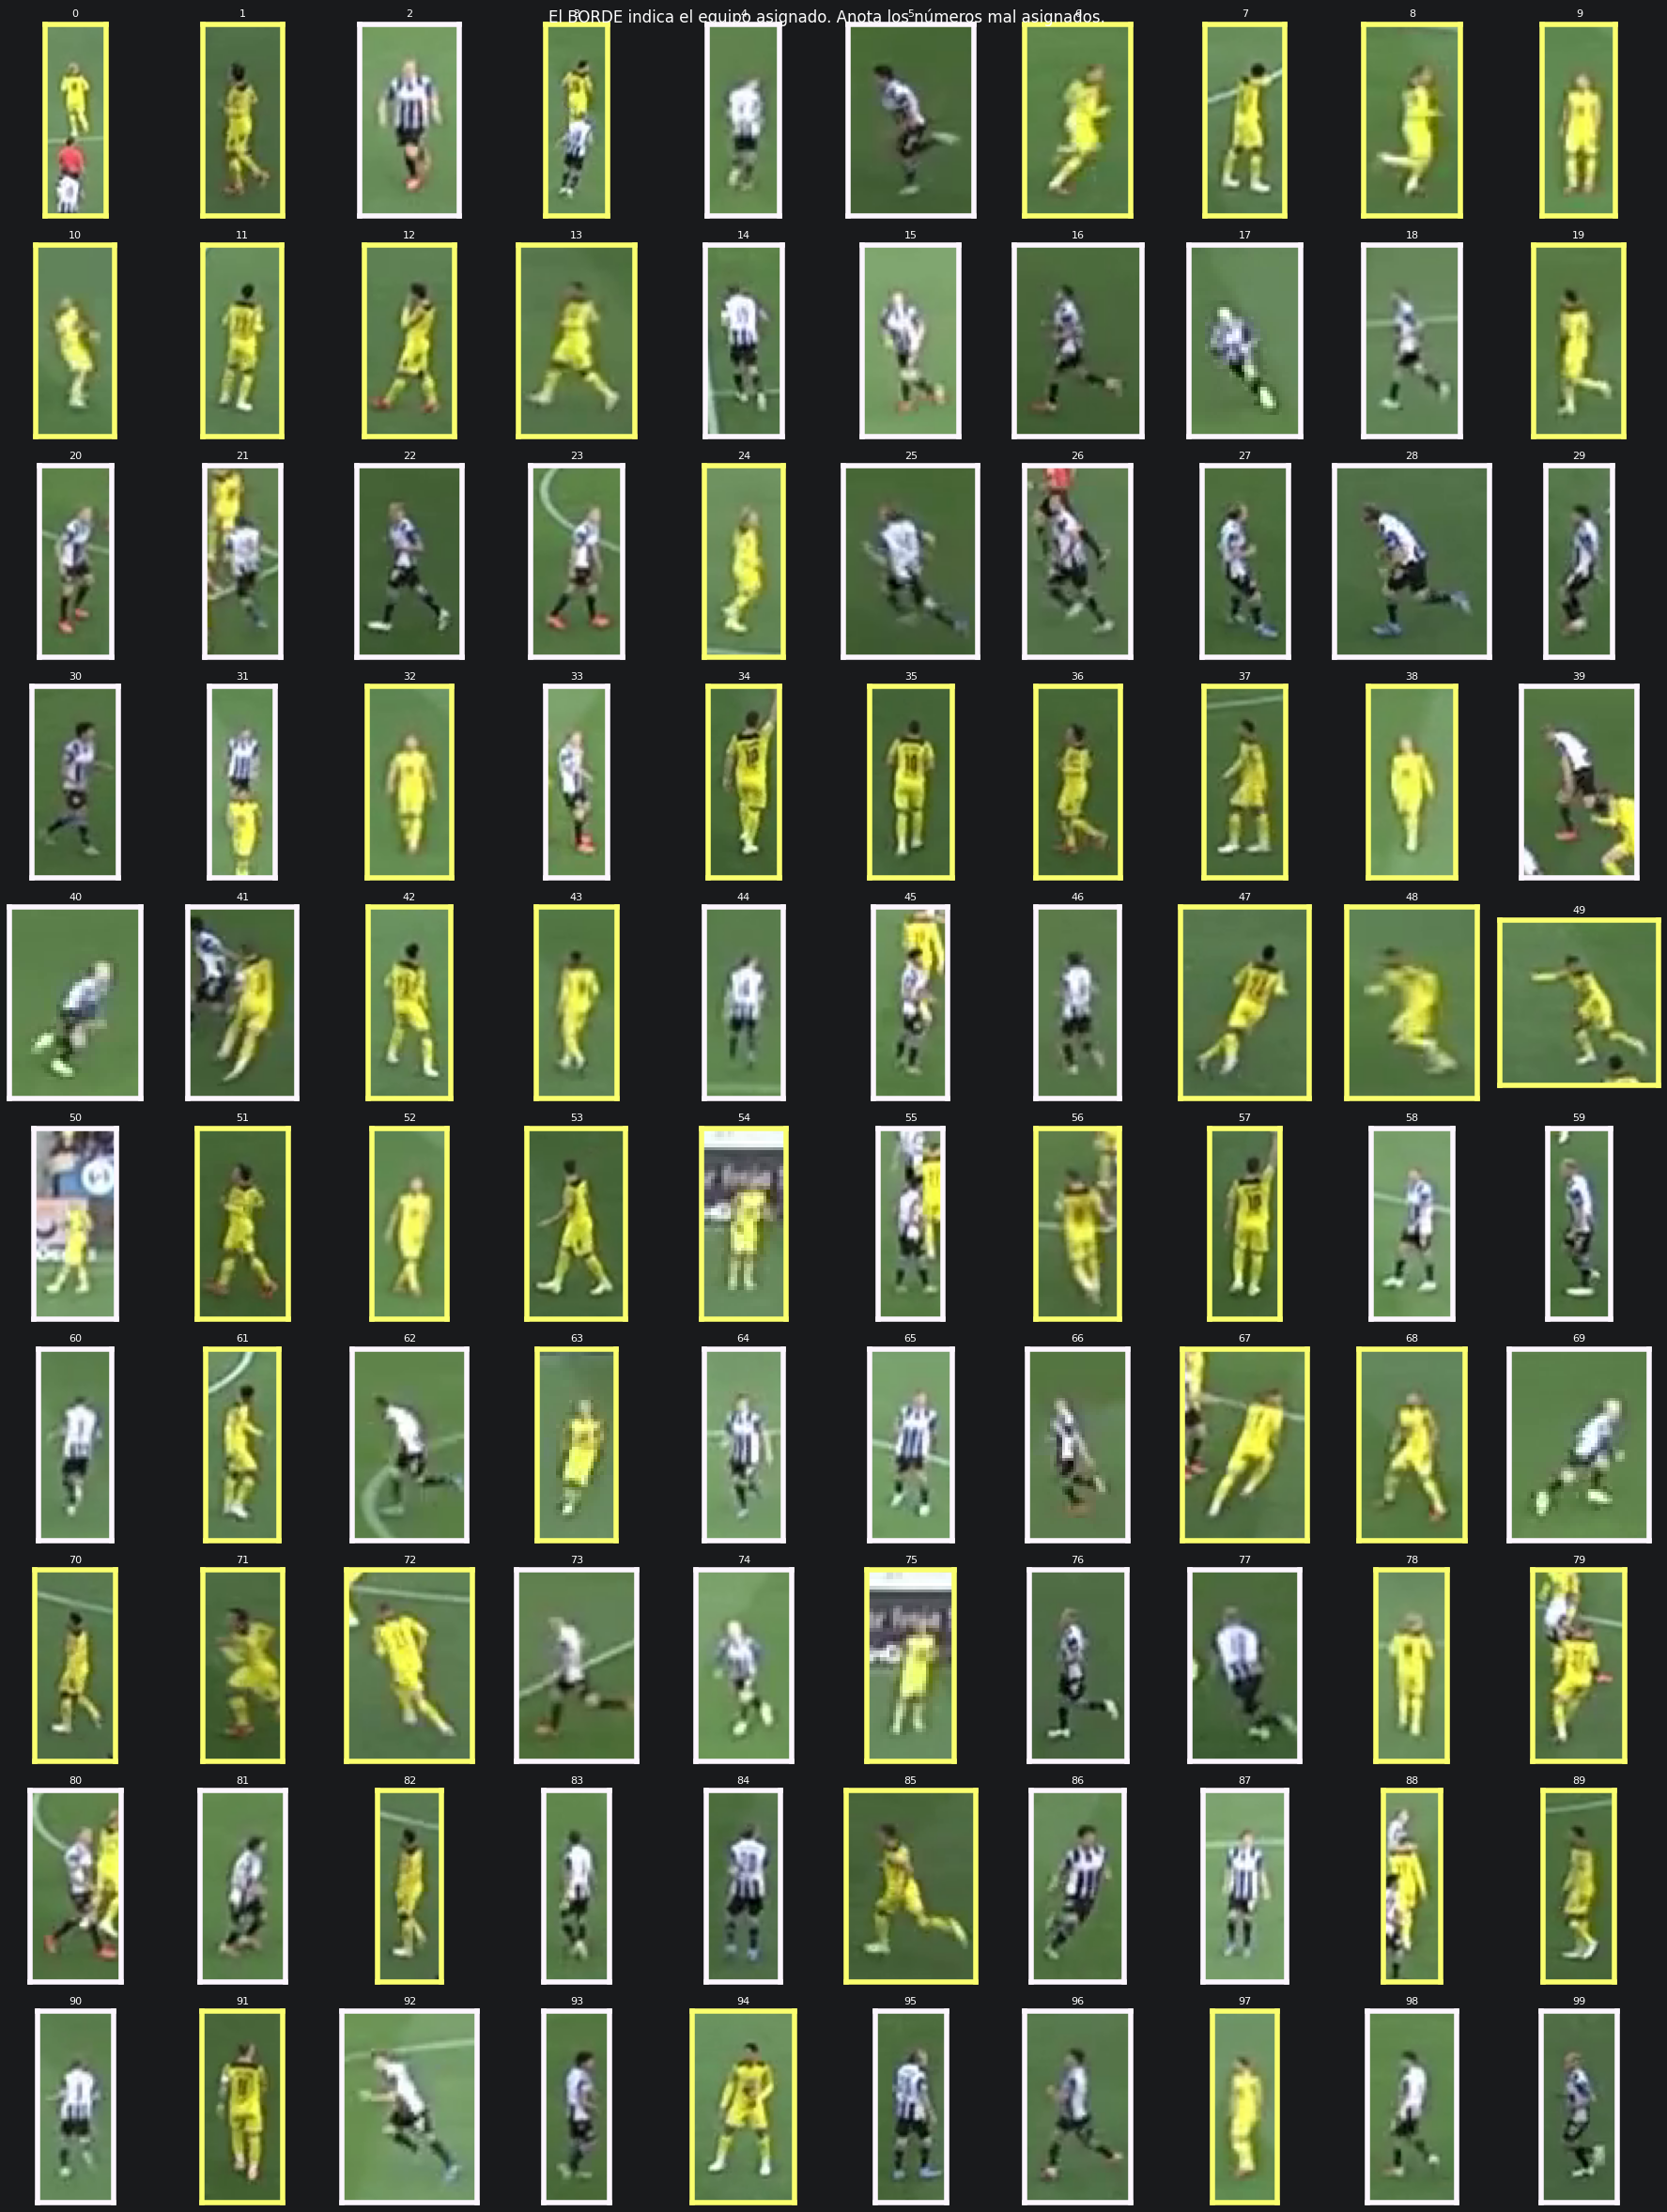

In [7]:
# ---- 6. Muestra de validación manual (solo jugadores de campo) ----
%matplotlib inline
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
candidatas = []
for f_idx, dets in enumerate(frames_track):
    for d in dets:
        if d["cls"] != 1:
            continue
        nid = id_final_det.get((f_idx, d["id"]))
        if rol_de.get(nid) == "jugador" and equipo_det.get((f_idx, d["id"])) in (0, 1):
            candidatas.append((f_idx, d["id"], d["bbox"], equipo_det[(f_idx, d["id"])]))

idxs = rng.choice(len(candidatas), min(100, len(candidatas)), replace=False)
muestra = [candidatas[i] for i in idxs]
imgs = {}
cap = cv2.VideoCapture(str(VIDEO_IN))
for f in sorted({m[0] for m in muestra}):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f)
    ret, fr = cap.read()
    if ret:
        imgs[f] = fr
cap.release()

cols = 10
rows = (len(muestra) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(18, 2.4 * rows))
for ax in np.ravel(axes):
    ax.axis("off")
for k, (f, tid, bbox, eq) in enumerate(muestra):
    x1, y1, x2, y2 = [int(v) for v in bbox]
    mx, my = int(0.15 * (x2 - x1)) + 3, int(0.1 * (y2 - y1)) + 3
    crop = imgs[f][max(y1 - my, 0):y2 + my, max(x1 - mx, 0):x2 + mx]
    ax = np.ravel(axes)[k]
    if crop.size > 0:
        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    b, g, r = np.array(color_equipo_bgr[eq]) / 255.0
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color((r, g, b)); sp.set_linewidth(4)
    ax.set_xticks([]); ax.set_yticks([]); ax.axis("on"); ax.set_title(f"{k}", fontsize=8)
plt.suptitle("El BORDE indica el equipo asignado. Anota los números mal asignados.")
plt.tight_layout()
plt.savefig(str(REPO_ROOT / "outputs" / f"validacion_muestra_{NOMBRE}.png"), dpi=110, bbox_inches="tight")
plt.show()

In [8]:
# ---- 7. Export del JSON integrado (interfaz de entrada de la fase 5) ----
import json

NOMBRE = VIDEO_IN.stem.replace(" ", "_").replace("(", "").replace(")", "")
OUT_JSON = REPO_ROOT / "data" / "tracking" / f"integrado_{NOMBRE}.json"
OUT_JSON.parent.mkdir(parents=True, exist_ok=True)

frames_json = []
for f_idx, dets in enumerate(frames_track):
    fr = []
    for d in dets:
        cls = d["cls"]
        item = {"id": int(d["id"]), "bbox": [float(v) for v in d["bbox"]], "cls": int(cls)}
        if cls in (1, 2):
            nid = id_final_det.get((f_idx, d["id"]))
            rol = rol_de.get(nid, "jugador" if cls == 1 else "arbitro")
            eq = equipo_seg.get(nid, equipo_det.get((f_idx, d["id"]), -1))
            if rol == "fuera":
                continue
            item["rol"] = rol
            item["equipo"] = int(eq) if eq in (0, 1) else -1
            p = campo_det.get((f_idx, d["id"]))
            item["campo"] = [float(p[0]), float(p[1])] if p is not None else None
        else:
            item["rol"] = "balon"
            item["equipo"] = -1
            item["campo"] = None
        fr.append(item)
    frames_json.append(fr)

payload = {
    "video": VIDEO_IN.name,
    "n_frames": len(frames_track),
    "color_equipo_bgr": {str(k): [int(v) for v in val] for k, val in color_equipo_bgr.items()},
    "frames": frames_json,
}
with open(OUT_JSON, "w", encoding="utf-8") as fh:
    json.dump(payload, fh, ensure_ascii=False)

# Diagnóstico de compresión: medir la dispersión de las posiciones de campo
import numpy as np
xs = [d["campo"][0] for fr in frames_json for d in fr
      if d.get("rol") in ("jugador", "portero") and d.get("campo")]
ys = [d["campo"][1] for fr in frames_json for d in fr
      if d.get("rol") in ("jugador", "portero") and d.get("campo")]
xs, ys = np.array(xs), np.array(ys)
n_jug = sum(1 for fr in frames_json for d in fr if d.get("rol") == "jugador")
n_gk = sum(1 for fr in frames_json for d in fr if d.get("rol") == "portero")
n_arb = sum(1 for fr in frames_json for d in fr if d.get("rol") == "arbitro")
print(f"JSON integrado guardado en: {OUT_JSON}")
print(f"Detecciones -> jugador: {n_jug} | portero: {n_gk} | arbitro: {n_arb}")
if len(xs):
    print(f"\n=== DIAGNÓSTICO DE COMPRESIÓN (campo 105x68 m) ===")
    print(f"X: min={xs.min():.1f} max={xs.max():.1f} -> ancho ocupado {xs.max()-xs.min():.1f} m de 105")
    print(f"Y: min={ys.min():.1f} max={ys.max():.1f} -> alto ocupado {ys.max()-ys.min():.1f} m de 68")
    print(f"Posiciones en mitad izquierda (X<52.5): {(xs<52.5).mean()*100:.0f}%")
    print(f"-> Si ancho < 60 m y >75% a la izquierda, la homografía comprime: hay que arreglarla antes de la pizarra")
else:
    print("Sin posiciones de campo: la homografía falló en todos los frames con jugadores")

JSON integrado guardado en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\tracking\integrado_test_27.json
Detecciones -> jugador: 15177 | portero: 174 | arbitro: 1241

=== DIAGNÓSTICO DE COMPRESIÓN (campo 105x68 m) ===
X: min=-2225.7 max=25256.6 -> ancho ocupado 27482.3 m de 105
Y: min=-9455.4 max=3095.1 -> alto ocupado 12550.5 m de 68
Posiciones en mitad izquierda (X<52.5): 51%
-> Si ancho < 60 m y >75% a la izquierda, la homografía comprime: hay que arreglarla antes de la pizarra
